# 03 · Imputation forensics: finding invented data

**Question.** The wage dataset this project inherited was gap-filled by an
undocumented heuristic. Which cells are real, which are invented, and how well
can a detector find invented cells without being told the formula?

**Why it matters.** Real wage growth is the project's headline indicator. A
growth rate with an invented endpoint is fiction presented as a measurement.

In [1]:
import sys, json, sqlite3
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = next(p for p in Path.cwd().resolve().parents if (p / "ml" / "src").is_dir())
sys.path.insert(0, str(ROOT / "ml" / "src"))
DB = ROOT / "data" / "realgrowth.db"
MODELS = ROOT / "data" / "models"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

def save(fig, name):
    path = FIG / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", dpi=130)
    plt.close(fig)
    display(Image(filename=str(path)))

## 1. The imputation formula

From `notebooks/cleaning.ipynb` (the original project), applied to wages, inflation,
debt and diet cost:

```python
world_avg = df[year_cols].mean()                       # cross-country mean per year
def fill_missing_with_ratio(row):
    ratios = row[available] / world_avg[available]
    mean_ratio = ratios.mean()
    row[year] = world_avg[year] * mean_ratio            # for every missing year
```

So every filled cell of country *c* in year *y* equals `r_c · w_y`. That leaves an
algebraic fingerprint: for any two filled years *a*, *b* of the same country,
`v_b / v_a = w_b / w_a`, **the same ratio for every country**. Wages were then
converted to USD; multiplying back by the same exchange rate (as the ETL does)
recovers the fingerprint exactly.

In [2]:
from realgrowth_ml.data import load_panel
from realgrowth_ml import anomaly
panel = load_panel(DB)
levels = panel.wide("avg_wage_lcu")
ratio = (levels[2022] / levels[2021]).round(6)
counts = ratio.value_counts()
print("Most common 2021->2022 wage growth ratios across countries:")
display(counts.head(5).rename("countries").to_frame())
print(f"{counts.iloc[0]} countries share the ratio {counts.index[0]} to 6 decimal places.")
print("Genuine wage data would essentially never do that.")

Most common 2021->2022 wage growth ratios across countries:


,countries
1.789,42
1.489,1
1.791,1
1.021,1
2.468,1


42 countries share the ratio 1.789205 to 6 decimal places.
Genuine wage data would essentially never do that.


## 2. Reconstructing the labels

`anomaly.reconstruct_labels` (1) finds every pair of years where ≥3 countries
share a growth ratio to 1e-6, (2) solves for the world index `w` by least squares
over all those pairwise links, then (3) marks every cell that sits on `r_c · w_y`
to 1e-6, iterating until stable. The method is validated on a simulation of the
notebook's exact algorithm, where it recovers the filled cells with zero errors
(`ml/tests/test_anomaly.py`).

514 of 2032 wage cells imputed (25.3%); 111 of 121 countries affected; 136 pairwise links; converged in 2 iterations


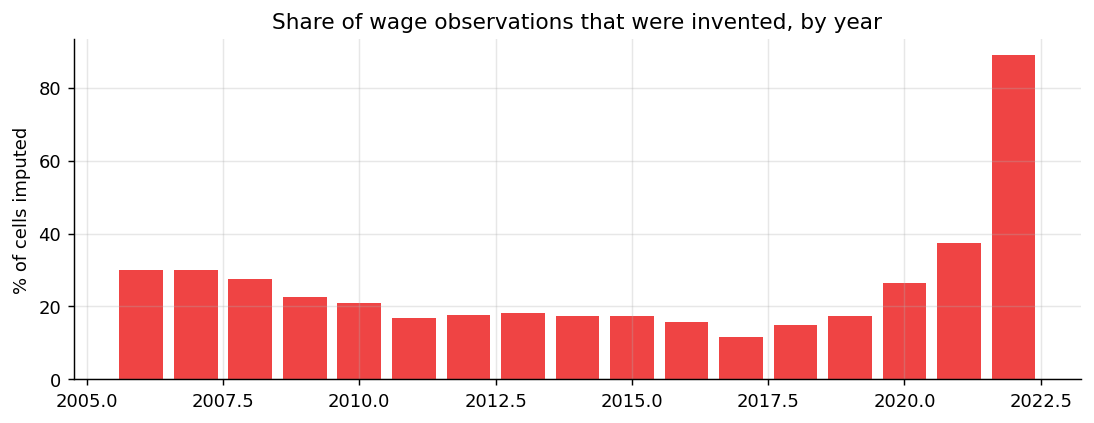

In [3]:
labels = anomaly.reconstruct_labels(levels)
d = labels.diagnostics
print(f"{d['imputed_cells']} of {d['observed_cells']} wage cells imputed ({d['imputed_share']:.1%}); "
      f"{d['countries_with_imputation']} of {d['countries']} countries affected; "
      f"{d['fingerprint_links']} pairwise links; converged in {d['iterations']} iterations")
by_year = pd.Series(d["imputed_by_year"]); total = levels.notna().sum()
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(by_year.index.astype(int), (by_year.values / total.values) * 100, color="#ef4444")
ax.set_ylabel("% of cells imputed"); ax.set_title("Share of wage observations that were invented, by year")
save(fig, "anomaly_imputed_by_year")

**89% of 2022 wage values were invented.** The original project's headline chart
— real wage growth in the 2022 cost-of-living crisis — was mostly computed from
imputed numbers. The latest year is where data is scarcest, and where a
`world average × ratio` fill is most tempting.

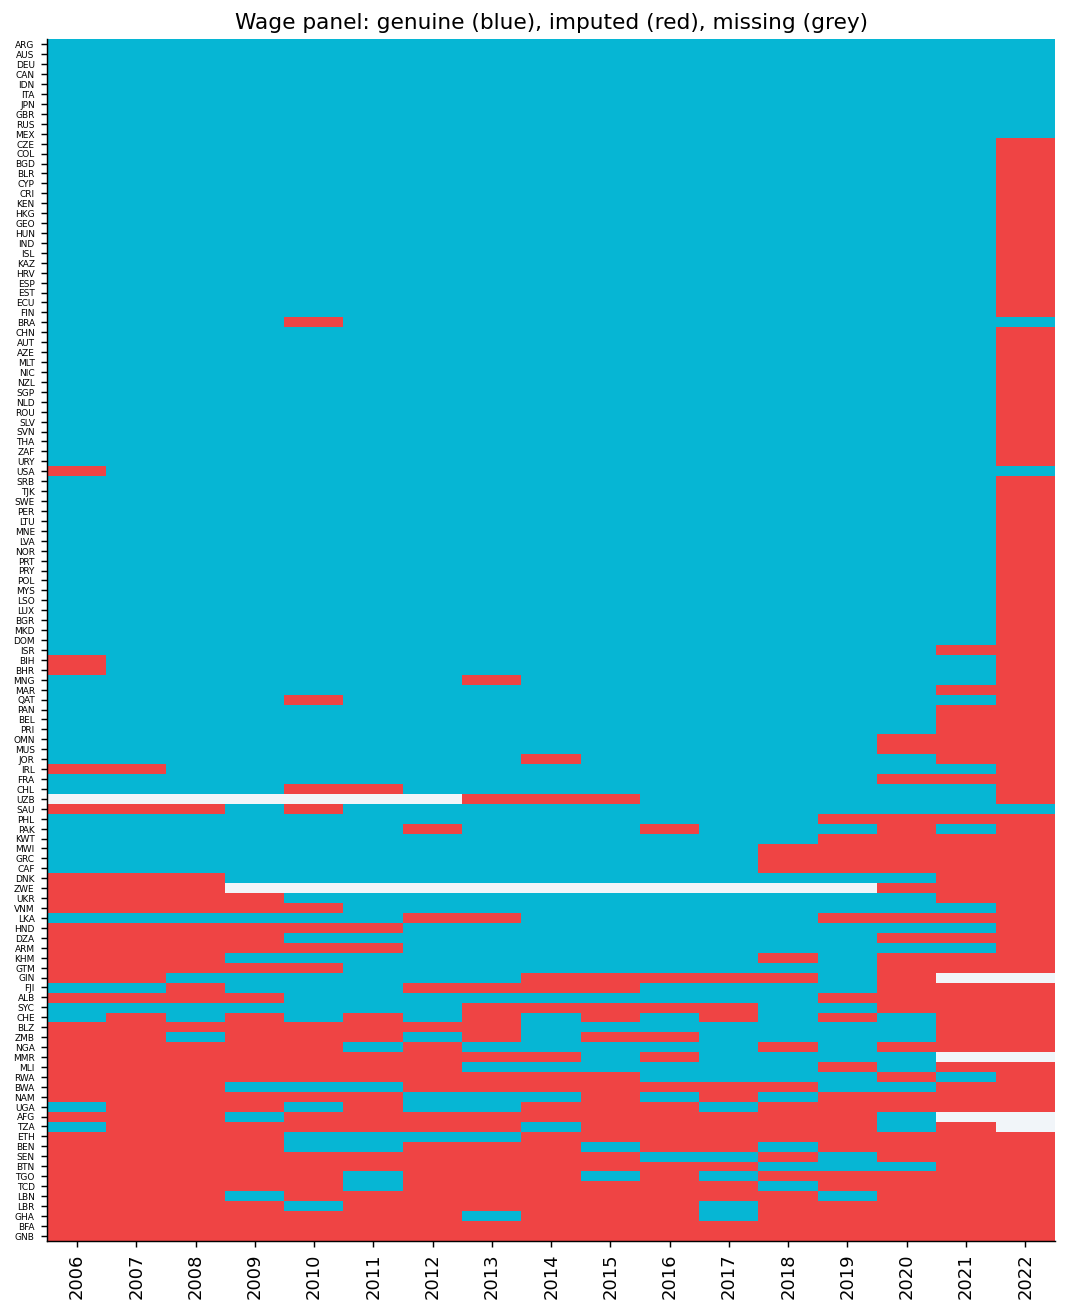

In [4]:
mat = labels.imputed.loc[levels.notna().any(axis=1)]
mat = mat.loc[mat.sum(axis=1).sort_values().index]
state = np.where(levels.loc[mat.index].isna(), 0, np.where(mat, 2, 1))
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(10, 12))
ax.imshow(state, aspect="auto", cmap=ListedColormap(["#f1f5f9", "#06b6d4", "#ef4444"]), interpolation="none")
ax.set_yticks(range(len(mat)), mat.index, fontsize=5); ax.set_xticks(range(len(mat.columns)), mat.columns, rotation=90)
ax.grid(False); ax.set_title("Wage panel: genuine (blue), imputed (red), missing (grey)")
save(fig, "anomaly_panel_map")

## 3. How good is the existing rule?

The ETL's rule rejects a wage move >40% that inflation ≥25% does not explain.
Judged at the level it operates (transitions), it is very **precise** but misses
most contaminated transitions, because most imputed cells produce small,
plausible-looking moves.

In [5]:
inflation = panel.wide("inflation_rate")
t = anomaly.rule_transition_metrics(levels, inflation, labels.imputed)
print(json.dumps({k: (round(v, 3) if isinstance(v, float) else v) for k, v in t.items()}, indent=1))

{
 "transitions": 1910,
 "rejected": 145,
 "contaminated": 558,
 "precision": 0.938,
 "recall": 0.244
}


## 4. Detectors compared

None of the detectors may use the fingerprint itself — the question is what a
*general-purpose* detector can recover, which matters for datasets where the
imputation formula is unknown. All supervised scores are **out-of-fold with
GroupKFold by country**, so a country is never scored by a model trained on it.

* **robust z-score** of inflation-adjusted growth (MAD-scaled, per country);
* **Isolation Forest**, unsupervised, on the detector features;
* **LightGBM, own-country features only** (ablation);
* **LightGBM, all features**, including cross-sectional deviation (how far a
  country's growth is from the year's cross-country median).

In [6]:
acard = json.loads((MODELS / "anomaly" / "model_card.json").read_text())
rows = []
for name, det in acard["detectors"].items():
    rows.append({"detector": name, "PR-AUC": det["pr_auc"], "ROC-AUC": det["roc_auc"],
                 "precision@rule budget": det["at_rule_budget"]["precision"],
                 "recall@rule budget": det["at_rule_budget"]["recall"],
                 "precision@0.5": (det.get("at_0_5") or {}).get("precision"),
                 "recall@0.5": (det.get("at_0_5") or {}).get("recall")})
display(pd.DataFrame(rows).set_index("detector").round(3))
print(f"base rate (share of cells imputed): {acard['base_rate']:.3f}")

,PR-AUC,ROC-AUC,precision@rule budget,recall@rule budget,precision@0.5,recall@0.5
detector,,,,,,
rule,NaN,NaN,0.599,0.323,NaN,NaN
robust_z,0.408,0.608,0.578,0.311,NaN,NaN
isolation_forest,0.516,0.757,0.646,0.348,NaN,NaN
lgbm_local,0.940,0.974,0.986,0.531,0.874,0.837
lgbm,0.967,0.984,0.996,0.537,0.932,0.877


base rate (share of cells imputed): 0.253


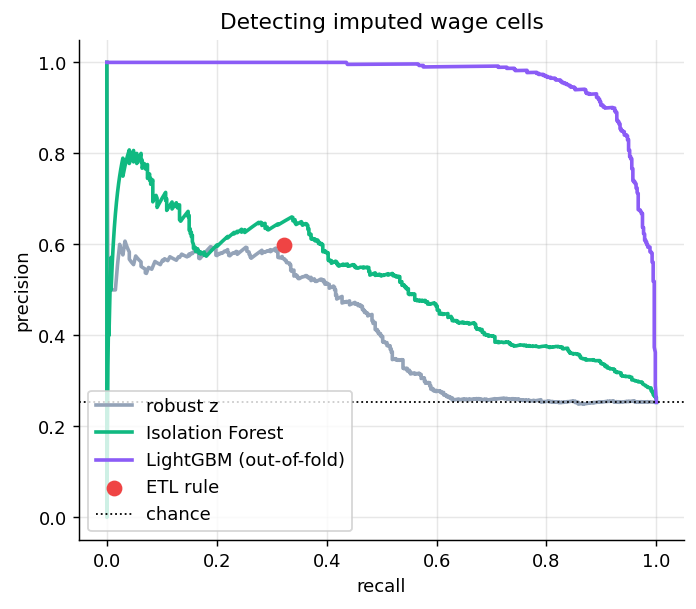

,feature,gain
0,xs_dev_out,4972
1,log_growth_out,3969
2,log_growth_in,2954
3,xs_dev_in,2643
4,level_dev,1513
5,abs_excess_max,917
6,excess_in,741
7,robust_z_in,617


In [7]:
from sklearn.metrics import precision_recall_curve
cells = pd.read_csv(MODELS / "anomaly" / "labelled_cells.csv")
fig, ax = plt.subplots(figsize=(6, 5))
for col, color, label in [("robust_z", "#94a3b8", "robust z"), ("isolation_forest", "#10b981", "Isolation Forest"),
                          ("lgbm", "#8b5cf6", "LightGBM (out-of-fold)")]:
    p, r, _ = precision_recall_curve(cells.label, cells[col])
    ax.plot(r, p, color=color, lw=2, label=label)
rule = acard["detectors"]["rule"]["at_rule_budget"]
ax.scatter([rule["recall"]], [rule["precision"]], color="#ef4444", zorder=3, s=60, label="ETL rule")
ax.axhline(acard["base_rate"], color="k", ls=":", lw=1, label="chance")
ax.set_xlabel("recall"); ax.set_ylabel("precision"); ax.legend(loc="lower left")
ax.set_title("Detecting imputed wage cells")
save(fig, "anomaly_pr_curves")
display(pd.DataFrame(acard["feature_importance_gain"]).head(8))

**Findings.**

* Unsupervised methods do only modestly better than the 0.25 base rate
  (PR-AUC 0.41 and 0.52): imputed cells are not *outliers*, they are smooth,
  plausible values. Outlier detection is the wrong tool for imputation detection.
* A supervised detector finds them with PR-AUC ≈ 0.97, mostly through
  cross-sectional features: imputed cells move *with the cross-country mean*,
  which genuine wages rarely do. Without those features (ablation) it still
  reaches ≈ 0.94.
* The labels made supervision possible. This is the general lesson: when you
  can reverse-engineer how bad data was produced, you can turn an unsupervised
  problem into a supervised one with exact labels.

## 5. What the pipeline does with this

The ETL now loads the exact labels and **refuses to compute a growth rate with an
imputed endpoint** (`imputed_input` issues), and flags every affected series in
the API and UI. The plausibility rule remains as a fallback for anything the
labels cannot see. The ML detector's scores are served at `/api/v1/anomalies`
for transparency and as a tool for other datasets with the same problem.

In [8]:
q = json.loads(sqlite3.connect(DB).execute("SELECT value FROM etl_metadata WHERE key='quality_report'").fetchone()[0])
cov = {c["indicator"]: c for c in q["coverage"]}
print("issue counts:", q["issue_counts"])
print("real wage growth now:", {k: cov["real_wage_growth"][k] for k in ["observations", "countries", "min_year", "max_year"]})

issue counts: {'implausible_growth': 9, 'imputed_input': 558, 'out_of_range': 17}
real wage growth now: {'observations': 1318, 'countries': 109, 'min_year': 2007, 'max_year': 2022}
